In [1]:
import pandas as pd
import ast
from pathlib import Path
import shutil
import matplotlib.pyplot as plt
import numpy as np
import os
import random
import wfdb
from collections import defaultdict
from collections import Counter

# **ANÁLISIS DE DATASETS DE SEÑALES**

In [2]:
# Rutas
RAW_PATH = r"C:\Users\Victoria\Desktop\Datos Señales Raw"
FILTERED_PATH = r"C:\Users\Victoria\Desktop\Datos Señales Filtered"
BALANCED_PATH = r"C:\Users\Victoria\Desktop\Datos Señales Balanced"

In [3]:
# Contar señales raw por dataset (excluyendo PTB-XL)
from collections import Counter

dataset_counts = Counter()
for root, dirs, files in os.walk(RAW_PATH):
    if 'ptb-xl' in root:
        continue
    dataset = root.replace(RAW_PATH, '').strip(os.sep).split(os.sep)[0]
    for file in files:
        if file.endswith('.hea'):
            dataset_counts[dataset] += 1

for ds, count in sorted(dataset_counts.items()):
    print(f"{ds}: {count}")
print(f"Total (sin PTB-XL): {sum(dataset_counts.values())}")
print(f"PTB-XL: {52720 - sum(dataset_counts.values())}")


chapman_shaoxing: 10247
cpsc_2018: 6877
cpsc_2018_extra: 3453
georgia: 10344
Total (sin PTB-XL): 30921
PTB-XL: 21799


## **PTB-XL** (referencia)

En este dataset, debido a su estructura particular, las etiquetas diagnósticas no se encuentran directamente en los archivos .hea, sino en los archivos de metadata:

- ptbxl_database.csv, que contiene los códigos asociados a cada señal
- scp_statements.csv, que define la interpretación clínica de dichos códigos

Para reconstruir la información clínica de cada registro, se procesó la columna scp_codes del archivo ptbxl_database.csv, la cual contiene diccionarios con los códigos asignados a cada señal. Este procesamiento se complementó con el archivo scp_statements.csv, que actúa como un diccionario de referencia para interpretar el significado médico de cada código.

El procedimiento de análisis consistió en validar cada código extraído de las señales frente al diccionario de referencia, conservando únicamente aquellos etiquetados como diagnósticos válidos y descartando comentarios sobre la forma de la onda o el ritmo. Una vez depurados, estos códigos se organizaron jerárquicamente según las categorías de subclase y superclase diagnóstica definidas por los autores del dataset. 

Este flujo de trabajo permitió identificar con precisión qué patologías específicas integran cada categoría funcional y determinar la frecuencia real con la que cada alteración clínica aparece en el dataset curado.

In [ ]:
# Cargar datos
ptb_df = pd.read_csv(r"C:\Users\Victoria\Desktop\Datos Señales Raw\ptb-xl\ptbxl_database.csv")
scp_df = pd.read_csv(r"C:\Users\Victoria\Desktop\Datos Señales Raw\ptb-xl\scp_statements.csv")

# Renombrar columna de códigos SCP
scp_df = scp_df.rename(columns={"Unnamed: 0": "scp_code"})

# Filtrar solo códigos diagnósticos
scp_df = scp_df[scp_df["diagnostic"] == 1]
ptb_df["scp_codes"] = ptb_df["scp_codes"].apply(ast.literal_eval)

# Contar ocurrencias de cada código SCP
contador = Counter()

for codes in ptb_df["scp_codes"]:
    for code in codes.keys():
        contador[code] += 1

scp_df = scp_df[scp_df["scp_code"].isin(contador.keys())]
scp_df = scp_df.sort_values(by=["diagnostic_class", "diagnostic_subclass"])

# Resultados
for superclase in scp_df["diagnostic_class"].dropna().unique():

    print("\n" + "="*40)
    print(f"🟦 {superclase}") # Superclase
    print("="*40)

    df_super = scp_df[scp_df["diagnostic_class"] == superclase]

    for subclase in df_super["diagnostic_subclass"].dropna().unique():
        print(f"\n  🔹 {subclase}") # Subclase

        df_sub = df_super[df_super["diagnostic_subclass"] == subclase] # Descripción

        for _, row in df_sub.iterrows():
            code = row["scp_code"]
            descripcion = row["description"]
            cantidad = contador.get(code, 0)

            print(f"     - {code}: {descripcion} ({cantidad} señales)")


🟦 CD

  🔹 CLBBB
     - CLBBB: complete left bundle branch block (536 señales)

  🔹 CRBBB
     - CRBBB: complete right bundle branch block (541 señales)

  🔹 ILBBB
     - ILBBB: incomplete left bundle branch block (77 señales)

  🔹 IRBBB
     - IRBBB: incomplete right bundle branch block (1118 señales)

  🔹 IVCD
     - IVCD: non-specific intraventricular conduction disturbance (block) (787 señales)

  🔹 LAFB/LPFB
     - LAFB: left anterior fascicular block (1623 señales)
     - LPFB: left posterior fascicular block (177 señales)

  🔹 WPW
     - WPW: Wolf-Parkinson-White syndrome (79 señales)

  🔹 _AVB
     - 1AVB: first degree AV block (793 señales)
     - 3AVB: third degree AV block (16 señales)
     - 2AVB: second degree AV block (14 señales)

🟦 HYP

  🔹 LAO/LAE
     - LAO/LAE: left atrial overload/enlargement (426 señales)

  🔹 LVH
     - LVH: left ventricular hypertrophy (2132 señales)

  🔹 RAO/RAE
     - RAO/RAE: right atrial overload/enlargement (99 señales)

  🔹 RVH
     - RVH: 

## **CPSC, Georgia y Chapman-Shaoxing**

Por otro lado, en estos datasets, las etiquetas diagnósticas se encuentran integradas en los archivos de cabecera (.hea), específicamente bajo el campo descriptivo #Dx. Estas etiquetas están codificadas mediante la nomenclatura internacional SNOMED-CT, la cual asigna un identificador numérico único a cada hallazgo clínico. El significado de cada uno de estos códigos es consultable a través de la web oficial de SNOMED.

El proceso de análisis consistió en la lectura sistemática de todos los archivos de cabecera para contabilizar la frecuencia de aparición de cada código único y determinar su interpretación médica. Este procedimiento permitió identificar con precisión la variedad de patologías presentes en los datasets y comprender la distribución clínica de los datos recolectados.


In [101]:
def analyze_labels(root_path):

    label_counts = defaultdict(int)  
    labels_per_signal = defaultdict(int)
    total_signals = 0

    for root, dirs, files in os.walk(root_path):

        # Excluimos PTB-XL del análisis
        if 'ptb-xl' in dirs:
            dirs.remove('ptb-xl')

        for file in files:
            if file.endswith(".hea"):

                total_signals += 1
                file_path = os.path.join(root, file)

                labels = []

                with open(file_path, 'r', encoding='latin1') as f:
                    for line in f:
                        if line.startswith("# Dx:"):
                            dx_line = line.strip().split(":")[1]
                            labels = [l.strip() for l in dx_line.split(",")]
                            break

                # Contar etiquetas individuales
                for label in labels:
                    label_counts[label] += 1

                # Contar cantidad de etiquetas por señal
                labels_per_signal[len(labels)] += 1

    return label_counts, labels_per_signal, total_signals

In [103]:
descriptions_SNOMED = {
    "426177001": "sinus bradycardia",
    "426783006": "sinus rhythm",
    "428750005": "nonspecific ST-T abnormality",
    "164934002": "T wave abnormal",
    "164889003": "atrial fibrillation",
    "427084000": "sinus tachycardia",
    "59118001": "right bundle branch block",
    "270492004": "1st degree AV block",
    "284470004": "premature atrial contraction",
    "164930006": "ST interval abnormal",
    "111975006": "prolonged QT interval",
    "164873001": "left ventricular hypertrophy",
    "429622005": "ST depression",
    "39732003": "left axis deviation",
    "55827005": "left ventricular hypertrophy",
    "164867002": "old myocardial infarction",
    "59931005": "T wave inversion",
    "425623009": "lateral ischemia",
    "67741000119109": "left atrial enlargement",
    "164884008": "ventricular ectopics",
    "164909002": "left bundle branch block",
    "164917005": "Q wave abnormal",
    "164890007": "atrial flutter",
    "17338001": "ventricular premature beats",
    "251146004": "low QRS voltages",
    "426761007": "supraventricular tachycardia",
    "164931005": "ST elevation",
    "713426002": "incomplete right bundle branch block",
    "427393009": "sinus arrhythmia",
    "425419005": "inferior ischemia",
    "698252002": "nonspecific intraventricular conduction disorder",
    "164865005": "myocardial infarction",
    "164861001": "myocardial ischemia",
    "47665007": "right axis deviation",
    "426434006": "anterior ischemia",
    "426627000": "bradycardia",
    "233917008": "AV block",
    "427172004": "premature ventricular contractions",
    "445118002": "left anterior fascicular block",
    "713422000": "atrial tachycardia",
    "251199005": "counterclockwise rotation",
    "428417006": "early repolarization",
    "413844008": "chronic myocardial ischemia",
    "713427006": "complete right bundle branch block",
    "251120003": "incomplete left bundle branch block",
    "6374002": "bundle branch block",
    "89792004": "right ventricular hypertrophy",
    "164912004": "P wave change",
    "251198002": "clockwise rotation",
    "266249003": "ventricular hypertrophy",
    "253352002": "left atrial abnormality",
    "54329005": "anterior myocardial infarction",
    "195126007": "atrial hypertrophy",
    "63593006": "supraventricular premature beats",
    "195042002": "2nd degree AV block",
    "251268003": "atrial pacing pattern",
    "251266004": "ventricular pacing pattern",
    "195080001": "atrial fibrillation and flutter",
    "446813000": "left atrial hypertrophy",
    "27885002": "complete heart block",
    "445211001": "left posterior fascicular block",
    "426995002": "junctional escape",
    "164937009": "U wave abnormal",
    "446358003": "right atrial hypertrophy",
    "195060002": "ventricular pre-excitation",
    "426664006": "accelerated junctional rhythm",
    "251166008": "AV nodal reentrant tachycardia",
    "253339007": "right atrial abnormality",
    "251180001": "ventricular trigeminy",
    "164896001": "ventricular fibrillation",
    "164947007": "prolonged PR interval",
    "251139008": "suspect lead reversal",
    "164921003": "R wave abnormal",
    "11157007": "ventricular bigeminy",
    "75532003": "ventricular escape beat",
    "195101003": "wandering atrial pacemaker",
    "65778007": "sinoatrial block",
    "67751000119106": "right atrial high voltage",
    "233897008": "AV reentrant tachycardia",
    "17366009": "wandering atrial rhythm",
    "55930002": "ST changes",
    "54016002": "Mobitz I AV block",
    "74390002": "Wolff-Parkinson-White pattern",
    "426648003": "junctional tachycardia",
    "29320008": "AV junctional rhythm",
    "49578007": "shortened PR interval",
    "251173003": "atrial bigeminy",
    "164942001": "fragmented QRS",
    "251164006": "junctional premature complex",
    "10370003": "pacing rhythm",
    "13640000": "fusion beats",
    "251170000": "blocked PAC",
    "413444003": "acute myocardial ischemia",
    "81898007": "ventricular escape rhythm",
    "370365005": "left ventricular strain",
    "74615001": "brady-tachy syndrome",
    "704997005": "inferior ST depression",
    "164895002": "ventricular tachycardia",
    "82226007": "diffuse intraventricular block",
    "111288001": "ventricular flutter",
    "251259000": "high T voltage",
    "77867006": "decreased QT interval",
    "426749004": "chronic atrial fibrillation"
}

In [104]:
label_counts, labels_per_signal, total_signals = analyze_labels(RAW_PATH)

print(f"\n🟦 Total de señales: {total_signals}")
print(f"🟦 Cantidad de etiquetas únicas: {len(label_counts)}\n")

print("\n📊 Cantidad de etiquetas por señal:")
for num_labels, count in sorted(labels_per_signal.items()):
    print(f"{num_labels} labels: {count} signals")


🟦 Total de señales: 30921
🟦 Cantidad de etiquetas únicas: 103


📊 Cantidad de etiquetas por señal:
1 labels: 17299 signals
2 labels: 7142 signals
3 labels: 3494 signals
4 labels: 1828 signals
5 labels: 760 signals
6 labels: 266 signals
7 labels: 97 signals
8 labels: 30 signals
9 labels: 3 signals
10 labels: 2 signals


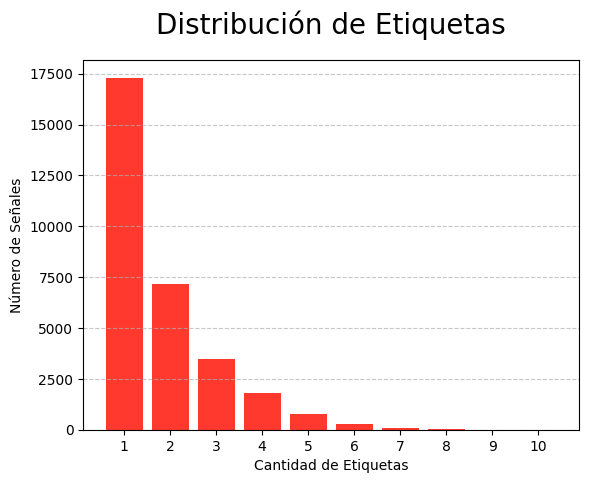

In [105]:
x = list(labels_per_signal.keys())        # Cantidad de etiquetas por señal
y = list(labels_per_signal.values())      # Cantidad de señales

# Distribucion de Etiquetas
plt.figure()
plt.bar(x, y, color="#ff392e")
plt.xlabel("Cantidad de Etiquetas")
plt.ylabel("Número de Señales")
plt.title("Distribución de Etiquetas", fontsize= 20, y=1.05)
plt.xticks(x)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

Los resultados muestran que la mayoría de las señales presentan una única etiqueta diagnóstica. Este comportamiento resulta favorable para el objetivo del trabajo, ya que facilita la posterior transformación del problema desde un enfoque *multi-label* a uno *multi-class*, donde cada señal es asociada a una única categoría.

In [106]:
print("📊 Frecuencia de etiquetas:")
for label, count in sorted(label_counts.items(), key=lambda x: x[1], reverse=True):
    # Buscamos la descripción en el diccionario
    descripcion = descriptions_SNOMED.get(label, "Unknown description")
    print(f"{label}: {descripcion} ({count})")

📊 Frecuencia de etiquetas:
426177001: sinus bradycardia (5611)
426783006: sinus rhythm (4500)
428750005: nonspecific ST-T abnormality (4331)
164934002: T wave abnormal (4204)
164889003: atrial fibrillation (3724)
427084000: sinus tachycardia (3132)
59118001: right bundle branch block (2854)
270492004: 1st degree AV block (1844)
284470004: premature atrial contraction (1586)
164930006: ST interval abnormal (1475)
111975006: prolonged QT interval (1452)
164873001: left ventricular hypertrophy (1405)
429622005: ST depression (1366)
39732003: left axis deviation (1322)
55827005: left ventricular hypertrophy (1295)
164867002: old myocardial infarction (1168)
59931005: T wave inversion (974)
425623009: lateral ischemia (903)
67741000119109: left atrial enlargement (871)
164884008: ventricular ectopics (741)
164909002: left bundle branch block (710)
164917005: Q wave abnormal (700)
164890007: atrial flutter (685)
17338001: ventricular premature beats (659)
251146004: low QRS voltages (623)
42

# **REMAPEO DE ETIQUETAS**

El objetivo de esta etapa es construir un dataset unificado de señales de ECG a partir de los diferentes repositorios mencionados anteriormente, transformando un esquema multi-etiqueta en un problema de clasificación multiclase, donde cada señal pertenece a una única categoría clínica. Dado que la mayoría de los datasets empleados utilizan la nomenclatura **SNOMED-CT** (Systematized Nomenclature of Medicine - Clinical Terms), caracterizada por su alta granularidad clínica, se realizó un proceso de simplificación de etiquetas mapeandolas a las cinco clases funcionales definidas por el dataset PDB: 

- NORM: Ritmos sinusales y variantes de normalidad
- CD: Trastornos de conducción (bloqueos de rama, bloqueos AV, etc.)
- MI: Infarto de miocardio (agudo o antiguo)
- HYP: Hipertrofias auriculares y ventriculares
- STTC: Alteraciones de la repolarización (segmento ST y onda T)

A partir de este esquema, se definió un diccionario de mapeo que asigna cada código SNOMED-CT a su correspondiente superclase.

In [ ]:
map_SNOMED = {
    # =========================
    # NORM (Normal)
    # =========================
    "426783006": "NORM",  # NORM: normal ECG


    # =========================
    # CD (Conduction Disorders)
    # =========================

    # Bundle branch blocks
    "6374002": "CD",    # BBB: bundle branch block (agregado nuestro)
    "164909002": "CD",  # LBBB: left bundle branch block (agregado nuestro)
    # " - ": "CD",      # CLBBB: complete left bundle branch block
    "251120003": "CD",  # ILBBB: incomplete left bundle branch block
    "59118001": "CD",   # RBBB: right bundle branch block (agregado nuestro)
    "713427006": "CD",  # CRBBB: complete right bundle branch block
    "713426002": "CD",  # IRBBB: incomplete right bundle branch block
    "698252002": "CD",  # IVCD: non-specific intraventricular conduction disturbance

    # Fascicular blocks
    "445118002": "CD",  # LAFB: left anterior fascicular block
    "445211001": "CD",  # LPFB: left posterior fascicular block

    # Pre-excitation
    "74390002": "CD",   # WPW: Wolff-Parkinson-White syndrome

    # AV blocks
    "233917008": "CD",  # AVB: AV block (agregado nuestro)
    "270492004": "CD",  # 1AVB: first degree AV block
    "195042002": "CD",  # 2AVB: second degree AV block
    "54016002": "CD",   # 2AVBII: Mobitz I AV block (agregado nuestro)
    "27885002": "CD",   # 3AVB: third degree AV block


    # =========================
    # HYP (Hypertrophy)
    # =========================

    # Ventricular hypertrophy
    "266249003": "HYP",  # VH: ventricular hypertrophy (agregado nuestro)
    "164873001": "HYP",  # LVH: left ventricular hypertrophy
    "55827005": "HYP",   # LVH: left ventricular hypertrophy
    "89792004": "HYP",   # RVH: right ventricular hypertrophy

    # Atrial hypertrophy
    "195126007": "HYP",  # AH: atrial hypertrophy (agregado nuestro)
    "446813000": "HYP",  # LAH: left atrial hypertrophy (agregado nuestro)
    "67741000119109": "HYP",  # LAO/LAE: left atrial enlargement
    "446358003": "HYP",  # RAO/RAE: right atrial enlargement

    # Septal hypertrophy
    #" - ": "HYP",  # SEHYP: septal hypertrophy


    # =========================
    # MI (Myocardial Infarction)
    # =========================
    "164865005": "MI",  # MI: myocardial infarction (agregado nuestro)
    "164867002": "MI",  # OMI: old myocardial infarction (agregado nuestro)

    # Anterior / septal / lateral
    # " - ": "MI",  # ASMI: anteroseptal myocardial infarction
    "54329005": "MI",  # AMI: anterior myocardial infarction
    # " - ": "MI",  # ALMI: anterolateral myocardial infarction
    # " - ": "MI",  # INJAS: subendocardial injury (anteroseptal)
    # " - ": "MI",  # INJAL: subendocardial injury (anterolateral)
    # " - ": "MI",  # INJLA: subendocardial injury (lateral)

    # Inferior
    # " - ": "MI",  # IMI: inferior myocardial infarction
    # " - ": "MI",  # ILMI: inferolateral myocardial infarction
    # " - ": "MI",  # IPLMI: inferoposterolateral myocardial infarction
    # " - ": "MI",  # IPMI: inferoposterior myocardial infarction
    # " - ": "MI",  # INJIN: subendocardial injury (inferior)
    # " - ": "MI",  # INJIL: subendocardial injury (inferolateral)

    # Otros
    # " - ": "MI",  # LMI: lateral myocardial infarction
    # " - ": "MI",  # PMI: posterior myocardial infarction


    # =========================
    # STTC (Repolarización)
    # =========================

    # Ischemias
    "164861001": "STTC",  # MIS: myocardial ischemia (agragdo nuestro)
    "413844008": "STTC",  # CMIS: chronic myocardial ischemia (agragdo nuestro)
    "413444003": "STTC",  # AMIS: acute myocardial ischemia (agragdo nuestro)
    # " - ": "STTC",      # ISCAL: ischemic anterolateral
    # " - ": "STTC",      # ISCAS: ischemic anteroseptal
    "425623009": "STTC",  # ISCLA: ischemic lateral
    "426434006": "STTC",  # ISCAN: ischemic anterior
    "425419005": "STTC",  # ISCIN: ischemic inferior
    # " - ": "STTC",      # ISCIL: ischemic inferolateral
    # " - ": "STTC",      # ISC_: non-specific ischemic

    # ST changes
    "55930002": "STTC",   # ST: ST changes
    "164931005": "STTC",  # STE: ST elevation (agragdo nuestro)
    "429622005": "STTC",  # STD: ST depression (agragdo nuestro)
    "164930006": "STTC",  # STA: ST interval abnormal (agragdo nuestro)
    
    "428750005": "STTC",  # NST_: non-specific ST changes

    # Otros
    "59931005": "STTC",   # TWI: T wave invesion (agragdo nuestro)
    "164934002": "STTC",  # NDT: non-diagnostic T abnormalities
    # " - ": "STTC",      # DIG: digitalis effect
    "111975006": "STTC",  # LNGQT: long QT interval
    # " - ": "STTC",      # ANEUR: ventricular aneurysm ST-T changes
    # " - ": "STTC",      # EL: electrolyte/drug effect
}

In [ ]:
# Recibe una lista de códigos SNOMED de una señal y devuelve su superclase.
def map_to_superclass(codes):
    classes = set() 
        
    for c in codes:
        if c in map_SNOMED:
            classes.add(map_SNOMED[c]) 

    # Solo se aceptan señales con una única superclase
    if len(classes) == 1:
        return list(classes)[0]
    else:
        return None # caso inválido (multi-clase o sin clase)



# Recibe una lista de códigos SNOMED y devuelve un string con sus descripciones.
def get_descriptions(codes):
   
    descrip = []
    for c in codes:
        descrip.append(descriptions_SNOMED.get(c, "unknown"))
    return "|".join(descrip)

In [ ]:
# Extrae los códigos SNOMED, la fs y la duración del archivo .hea de una señal
def read_hea(file_path):
    snomed_codes = []
    fs = None
    length = None

    # Leer archivo
    with open(file_path, 'r', encoding='latin1') as f:
        lines = f.readlines()

        # Info general
        first_line = lines[0].split()
        if len(first_line) >= 4:
            fs = int(first_line[2])     # fs
            length = int(first_line[3]) # Cantidad de muestras

        # Etiquetas
        for line in lines:
            if line.startswith("# Dx:"):
                dx = line.split(":", 1)[1]
                snomed_codes = [x.strip() for x in dx.split(",")]
                break

    # Calcular duración
    duration = length / fs if fs and length else None

    return snomed_codes, fs, duration



# Corrije el nombre de archivo en el .hea
def fix_hea_file(src_hea, dst_hea, new_base_name):
    with open(src_hea, "r", encoding="latin1") as f:
        lines = f.readlines()

    # Nombre original
    old_base = lines[0].split()[0]

    new_lines = []

    for line in lines:
        # Reemplazar nombre base en toda la línea
        line = line.replace(old_base, new_base_name)
        new_lines.append(line)

    with open(dst_hea, "w", encoding="latin1") as f:
        f.writelines(new_lines)

Para que una señal sea incluida en el dataset debe cumplir con al menos una de las siguientes condiciones:

- Presenta una única etiqueta diagnóstica
- Todas sus etiquetas corresponden a una misma superclase

En caso contrario, si la señal presenta múltiples superclases o no podía mapearse a ninguna, se descarta. Adicionalmente, se excluyeron aquellas señales cuya duración fuera menor a 6 segundos, ya que no permiten generar imágenes con el mismo formato que las utilizadas en el dataset del ICBA, lo cual es un requisito para la etapa posterior de generación de imágenes sintéticas.



In [ ]:
def process_dataset():
    records = []
    new_id = 0
    total_raw = 0
    discard_no_label = 0
    discard_multiclass = 0
    discard_short = 0

    # Recorre cada dataset dentro de la carpeta
    for dataset in os.listdir(RAW_PATH):
        dataset_path = os.path.join(RAW_PATH, dataset)

        # ------------- PTB-XL ------------------
        if dataset.lower() == "ptb-xl":

            # Leer archivos CSV con metadata
            df = pd.read_csv(os.path.join(dataset_path, "ptbxl_database.csv"), index_col="ecg_id")
            scp_df = pd.read_csv(os.path.join(dataset_path, "scp_statements.csv"), index_col=0)
            df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)

            # Filtrar solo códigos diagnósticos
            diag_df = scp_df[scp_df["diagnostic"] == 1] 

            # Obtener superclase
            def get_superclass(scp_codes):
                classes = set()
                for code in scp_codes.keys():
                    if code in diag_df.index:
                        cls = diag_df.loc[code, "diagnostic_class"]
                        if pd.notna(cls):
                            classes.add(cls)
                return list(classes)

            df["superclasses"] = df["scp_codes"].apply(get_superclass)



            for ecg_id, row in df.iterrows():

                total_raw += 1
                classes = row["superclasses"]

                # Filtrar señales
                # ❌ sin label
                if len(classes) == 0:
                    discard_no_label += 1
                    continue

                # ❌ multiclase
                if len(classes) > 1:
                    discard_multiclass += 1
                    continue

                superclass = classes[0]

                # usar SOLO 500 Hz
                rel_path = row["filename_hr"]
                base = os.path.basename(rel_path)

                src_dat = os.path.join(dataset_path, rel_path + ".dat")
                src_hea = os.path.join(dataset_path, rel_path + ".hea")

                if not os.path.exists(src_dat):
                    continue

                # ❌ duración
                duration = 10
                if duration < 6:
                    discard_short += 1
                    continue

                # Renombrar archivo
                new_filename = f"{new_id:06d}.dat"
                dst_dat = os.path.join(FILTERED_PATH, new_filename)
                dst_hea = os.path.join(FILTERED_PATH, new_filename.replace(".dat", ".hea"))

                # Copiar archivo a carpeta final
                shutil.copy(src_dat, dst_dat)
                new_base = f"{new_id:06d}"
                fix_hea_file(src_hea, dst_hea, new_base)

                # Guardar registro en csv
                record = {
                    "id": new_id,
                    "filename": new_filename,
                    "format": "dat",
                    "superclass": superclass,
                    "snomed_codes": "",
                    "snomed_descriptions": "",
                    "num_labels": 1,
                    "length_sec": duration,
                    "fs": 500,
                    "original_filename": base + ".dat",
                    "dataset": "ptb-xl"
                }

                # Agregar datos al dataframe
                records.append(record) 
                new_id += 1

       
        # ----- CPSC, Georgia y Chapman-Shaoxing -----
        else:

            for root, _, files in os.walk(dataset_path):

                for file in files:
                    # Solo procesamos archivos .hea (metadata)
                    if not file.endswith(".hea"):
                        continue

                    total_raw += 1
                    hea_path = os.path.join(root, file)
                    snomed_codes, fs, duration = read_hea(hea_path)

                    # Filtrar señales
                    # ❌ sin label
                    if not snomed_codes:
                        discard_no_label += 1
                        continue

                    # ❌ duración
                    if duration is None or duration < 6:
                        discard_short += 1
                        continue

                    # ❌ multiclase
                    superclass = map_to_superclass(snomed_codes)
                    if superclass is None:
                        discard_multiclass += 1
                        continue

                    base = file.replace(".hea", "")
                    signal_file = None
                    format_type = None

                    # Buscar archivo asociado
                    for ext in [".mat", ".dat"]:
                        candidate = os.path.join(root, base + ext)
                        if os.path.exists(candidate):
                            signal_file = candidate
                            format_type = ext.replace(".", "")
                            break

                    if signal_file is None:
                        continue

                    # Renombrar archivo   
                    new_filename = f"{new_id:06d}.{format_type}"
                    dst_signal = os.path.join(FILTERED_PATH, new_filename)
                    dst_hea = os.path.join(FILTERED_PATH, new_filename.replace(f".{format_type}", ".hea"))

                    # Copiar archivo a carpeta final
                    shutil.copy(signal_file, dst_signal)
                    new_base = f"{new_id:06d}"
                    fix_hea_file(hea_path, dst_hea, new_base)

                    # Guardar archivo
                    record = {
                        "id": new_id,
                        "filename": new_filename,
                        "format": format_type,
                        "superclass": superclass,
                        "snomed_codes": "|".join(snomed_codes),
                        "snomed_descriptions": get_descriptions(snomed_codes),
                        "num_labels": len(snomed_codes),
                        "length_sec": duration,
                        "fs": fs,
                        "original_filename": base + "." + format_type,
                        "dataset": dataset
                    }

                    # Agregar datos al dataframe
                    records.append(record)
                    new_id += 1

    df = pd.DataFrame(records)

    return df, total_raw, discard_no_label, discard_multiclass, discard_short


Las señales conservadas fueron renombradas de forma secuencial y almacenadas en una nueva carpeta unificada, junto con sus respectivos archivos .hea. Además, se generó un archivo Dataset Señales.csv que contiene la metadata estructurada de cada señal, incluyendo:

- id: identificador único
- filename: nombre del archivo en el nuevo dataset
- format: tipo de archivo (.mat o .dat)
- superclass: etiqueta final
- snomed_codes: códigos originales
- snomed_descriptions: descripciones clínicas
- num_labels: cantidad de etiquetas originales
- length_sec: duración de la señal
- fs: frecuencia de muestreo
- original_filename: nombre original del archivo
- dataset: dataset de origen 

In [ ]:
# Procesar señales
signal_data, total_raw, discard_no_label, discard_multi, discard_short = process_dataset()

# Guardar CSV
signal_data.to_csv(
    os.path.join(FILTERED_PATH, "Dataset Señales Filtered.csv"),
    index=False)

# **ANÁLISIS DEL DATASET CURADO**

In [ ]:
total_filtered = len(signal_data)
discard_total = discard_no_label + discard_multi + discard_short

print("\n" + "="*50)
print("🧹 FILTRADO DEL DATASET")
print("="*50)

print(f"Total inicial:     {total_raw}")
print(f"Señales conservadas: {total_filtered} ({(total_filtered/total_raw)*100:.1f}%)")
print(f"Señales descartadas: {discard_total} ({(discard_total/total_raw)*100:.1f}%)\n")

print("Desglose de descartes:")

print(f" - Sin mapeo:           {discard_no_label:>6} ({(discard_no_label/total_raw)*100:.1f}%)")
print(f" - Multiclase:          {discard_multi:>6} ({(discard_multi/total_raw)*100:.1f}%)")
print(f" - Longitud insuficiente:{discard_short:>6} ({(discard_short/total_raw)*100:.1f}%)")


🧹 FILTRADO DEL DATASET
Total inicial:     52720
Señales conservadas: 34192 (64.9%)
Señales descartadas: 18522 (35.1%)

Desglose de descartes:
 - Sin mapeo:              411 (0.8%)
 - Multiclase:           18059 (34.3%)
 - Longitud insuficiente:    52 (0.1%)


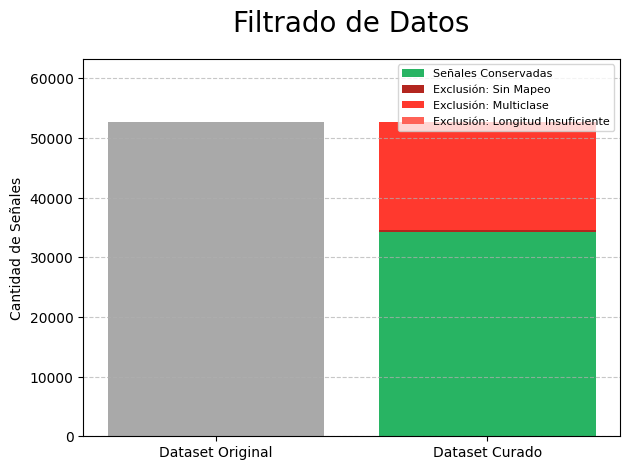

In [87]:
labels = ["Dataset Original", "Dataset Curado"]
kept_signals = len(signal_data)

plt.figure()

# Barra del Dataset Original
plt.bar(labels[0], total_raw, color="#A9A9A9", label="_nolegend_")

# Barra del Dataset Curado
# Señales conservadas (verde)
plt.bar(labels[1], kept_signals, color="#28B463", label="Señales Conservadas")
# Señales descartadas (rojo)
plt.bar(labels[1], discard_no_label, bottom=kept_signals, 
        color="#b3261f", label="Exclusión: Sin Mapeo")
plt.bar(labels[1], discard_multi, bottom=kept_signals + discard_no_label, 
        color="#ff392e", label="Exclusión: Multiclase")
plt.bar(labels[1], discard_short, bottom=kept_signals + discard_no_label + discard_multi, 
        color="#ff6257", label="Exclusión: Longitud Insuficiente")

# Ejes
plt.ylabel("Cantidad de Señales", fontsize=10)
plt.title("Filtrado de Datos", fontsize=20, y=1.05)
plt.ylim(0, total_raw * 1.2)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Leyenda
plt.legend(loc="upper right", fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

El proceso de curado permitió conservar 34,192 señales (64.9%) del total original de 52,720 registros, lo que indica una reducción moderada del dataset sin pérdida excesiva de información. El principal motivo de descarte fue la presencia de múltiples superclases por señal (34.3%), lo cual era esperable dado que los datasets originales presentan una naturaleza multi-etiqueta.

In [ ]:
# Cantidad de señales por clase y por dataset
total_filtered = len(signal_data)

print("\n" + "="*50)
print("📊 ANÁLISIS DEL DATASET")
print("="*50)

print(f"Dataset original: {total_raw}")
print(f"Dataset curado:   {total_filtered}")

print("\nDistribución por clase:\n")

# Conteo por clase
class_counts = signal_data["superclass"].value_counts()

for cls in ["NORM", "CD", "MI", "HYP", "STTC"]:
    if cls not in class_counts:
        continue

    total_cls = class_counts[cls]
    pct_cls = (total_cls / total_filtered) * 100

    print(f"{cls:<6} {total_cls:>6} ({pct_cls:>5.1f}%)")

    # Desglose por dataset dentro de la clase
    subset = signal_data[signal_data["superclass"] == cls]
    dataset_counts = subset["dataset"].value_counts()

    for ds, count in dataset_counts.items():
        pct_ds = (count / total_cls) * 100
        print(f"   └─ {ds:<20} {count:>6} ({pct_ds:>5.1f}%)")

    print()


📊 ANÁLISIS DEL DATASET
Dataset original: 52720
Dataset curado:   34192

Distribución por clase:

NORM    13179 ( 38.5%)
   └─ ptb-xl                 9069 ( 68.8%)
   └─ georgia                1735 ( 13.2%)
   └─ chapman_shaoxing       1457 ( 11.1%)
   └─ cpsc_2018               918 (  7.0%)

CD       6055 ( 17.7%)
   └─ cpsc_2018              2740 ( 45.3%)
   └─ ptb-xl                 1708 ( 28.2%)
   └─ georgia                 942 ( 15.6%)
   └─ chapman_shaoxing        629 ( 10.4%)
   └─ cpsc_2018_extra          36 (  0.6%)

MI       3353 (  9.8%)
   └─ ptb-xl                 2532 ( 75.5%)
   └─ cpsc_2018_extra         812 ( 24.2%)
   └─ chapman_shaoxing          9 (  0.3%)

HYP      1908 (  5.6%)
   └─ georgia                 735 ( 38.5%)
   └─ chapman_shaoxing        615 ( 32.2%)
   └─ ptb-xl                  535 ( 28.0%)
   └─ cpsc_2018_extra          23 (  1.2%)

STTC     9697 ( 28.4%)
   └─ georgia                2991 ( 30.8%)
   └─ ptb-xl                 2400 ( 24.7%)
   └─ cha

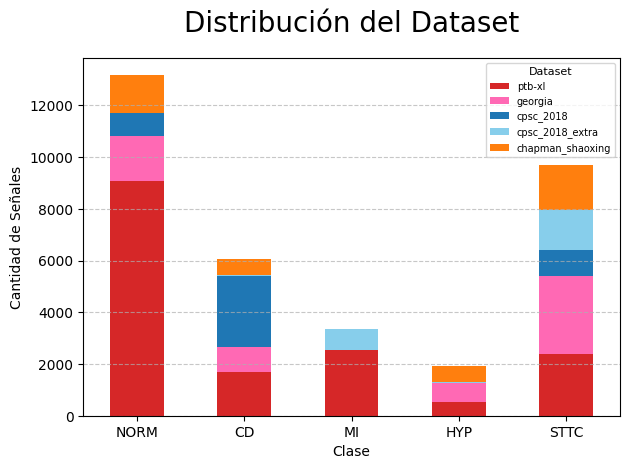

In [ ]:
counts = signal_data.groupby(["superclass", "dataset"]).size().unstack(fill_value=0)
class_order = ["NORM", "CD", "MI", "HYP", "STTC"]
counts = counts.reindex(class_order)
color_map = {
    "ptb-xl": "#d62728",            # rojo
    "georgia": "#ff69b4",           # rosa
    "cpsc_2018": "#1f77b4",         # azul
    "cpsc_2018_extra": "#87ceeb",   # celeste
    "chapman_shaoxing": "#ff7f0e"   # naranja
}
# Asegurar orden consistente de columnas
counts = counts[[c for c in color_map.keys() if c in counts.columns]]

# Colores en orden correcto
colors = [color_map[c] for c in counts.columns]

# Mostrar resultados
counts.plot(kind="bar", stacked=True, color=colors)

plt.xlabel("Clase")
plt.ylabel("Cantidad de Señales")
plt.title("Distribución del Dataset", fontsize=20, y=1.05)

plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Dataset", loc="upper right", fontsize=7,
    title_fontsize=8, frameon=True)
    
plt.tight_layout()
plt.show()

El dataset resultante presenta desbalance entre clases, con predominio de registros normales y menor representación de patologías específicas como hipertrofia e infarto de miocardio. En particular, la clase mayoritaria (NORM) contiene aproximadamente 7 veces más muestras que la clase minoritaria (HYP), lo que evidencia un desbalance significativo en la distribución de los datos. Sin embargo, este comportamiento también refleja en parte la frecuencia real de aparición de estas condiciones en contextos clínicos.

Asimismo, se observa que ciertas clases dependen fuertemente de un único dataset (como MI en PTB-XL), mientras que otras muestran una distribución más homogénea entre múltiples fuentes (como STTC), lo cual podría impactar en la capacidad de generalización de los modelos.